# Lab 1: Vacuum Cleaner Agent (4 rooms)

Environment (Anaconda): `conda create -n ailab python=3.11 numpy pandas matplotlib jupyter`, then `conda activate ailab` and `jupyter notebook`.

Run cells from top to bottom with **Shift+Enter**.

**PEAS:** performance = +1 per clean room per step; environment = 4 rooms with initially random dirt and optional dirt recurrence; actuators = Left/Right/Suck/NoOp; sensors = current position and current-room status.

This version compares three agents under four probabilities of dirt reappearing: 0%, 1%, 5%, and 10% per clean room per step.


## Cell 1: Setup (ready-made libraries)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_ROOMS = 4
STEPS = 50
RUNS = 100
P_DIRT = 0.05

AGENTS = ("random", "reflex", "model")
DIRT_PROBABILITIES = (0.0, 0.01, 0.05, 0.10)


## Cell 2: Simulation function with recurring dirt

Each run starts with the same initial-room state and uses a pre-generated schedule of possible dirt events. This makes comparisons between agents fairer for a given seed.

In [2]:
def simulate(agent, seed, dirt_recurrence=P_DIRT):
    """Run one vacuum-agent simulation and return its cumulative score."""
    if agent not in AGENTS:
        raise ValueError(f"Unknown agent: {agent}")

    if not np.isfinite(dirt_recurrence) or not 0 <= dirt_recurrence <= 1:
        raise ValueError("dirt_recurrence must be between 0 and 1")

    # Separate random generators so agents share the initial state and
    # environmental dirt-event schedule for a given seed.
    initial_rng = np.random.default_rng(seed)
    action_rng = np.random.default_rng(seed + 1_000_000)
    environment_rng = np.random.default_rng(seed + 2_000_000)

    # True means dirty.
    dirt = initial_rng.random(N_ROOMS) < 0.5
    known_clean = np.zeros(N_ROOMS, dtype=bool)

    pos = 0
    direction = 1
    score = 0

    # True means that room becomes dirty during that step if it is clean.
    dirt_events = environment_rng.random((STEPS, N_ROOMS)) < dirt_recurrence

    for step in range(STEPS):
        # Observe the current room.
        known_clean[pos] = not dirt[pos]

        # Choose an action.
        if agent == "random":
            action = action_rng.choice(("Left", "Right", "Suck"))
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = action_rng.choice(("Left", "Right"))
        else:  # model-based agent
            # Previously clean observations remain reliable only in a static world.
            if dirt_recurrence == 0.0 and known_clean.all():
                action = "NoOp"
            else:
                # Patrol continually when dirt can reappear.
                if pos == N_ROOMS - 1:
                    direction = -1
                elif pos == 0:
                    direction = 1
                action = "Right" if direction == 1 else "Left"

        # Execute the action.
        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)
        # NoOp leaves the agent and room unchanged.

        # Dirt may reappear in rooms that are currently clean.
        new_dirt = dirt_events[step] & (~dirt)
        dirt |= new_dirt

        # One point for every room that is clean at the end of this step.
        score += int(np.count_nonzero(~dirt))

    return score


## Cell 3: Quick test of the 3 agents

This smoke test runs each agent once with the default recurrence probability (`P_DIRT = 0.05`).

In [ ]:
print("Single-run scores (seed=1):")
for agent in AGENTS:
    print(agent, simulate(agent, seed=1, dirt_recurrence=P_DIRT))


## Cell 4: Run experiments across dirt probabilities

For every probability, run each agent `RUNS` times. Each row records one independent seed/run.

In [3]:
rows = []

for p in DIRT_PROBABILITIES:
    for agent in AGENTS:
        for seed in range(RUNS):
            score = simulate(agent, seed=seed, dirt_recurrence=p)
            rows.append({
                "agent": agent,
                "dirt_probability": p,
                "seed": seed,
                "score": score,
            })

df = pd.DataFrame(rows)
print(df.head())
print(f"\nTotal runs: {len(df)}")


    agent  dirt_probability  seed  score
0  random               0.0     0    182
1  random               0.0     1    198
2  random               0.0     2    170
3  random               0.0     3    175
4  random               0.0     4    175

Total runs: 1200


## Cell 5: Summary table

The mean describes average performance; the standard deviation (`std`) describes run-to-run variability.

In [4]:
summary = (
    df.groupby(["dirt_probability", "agent"])["score"]
    .agg(["mean", "std"])
    .round(2)
)

print("Experimental results:")
print(summary)


Experimental results:
                           mean    std
dirt_probability agent                
0.00             model   195.74   2.91
                 random  168.53  26.43
                 reflex  189.27  10.37
0.01             model   190.43   5.08
                 random  149.20  28.14
                 reflex  180.91  12.11
0.05             model   166.47  10.88
                 random  101.79  23.77
                 reflex  147.30  17.02
0.10             model   135.75  14.68
                 random   70.59  17.76
                 reflex  115.95  18.09


## Cell 6: Plot mean score and standard deviation

Each line represents an agent. Error bars show ±1 standard deviation across the 100 runs for that probability.

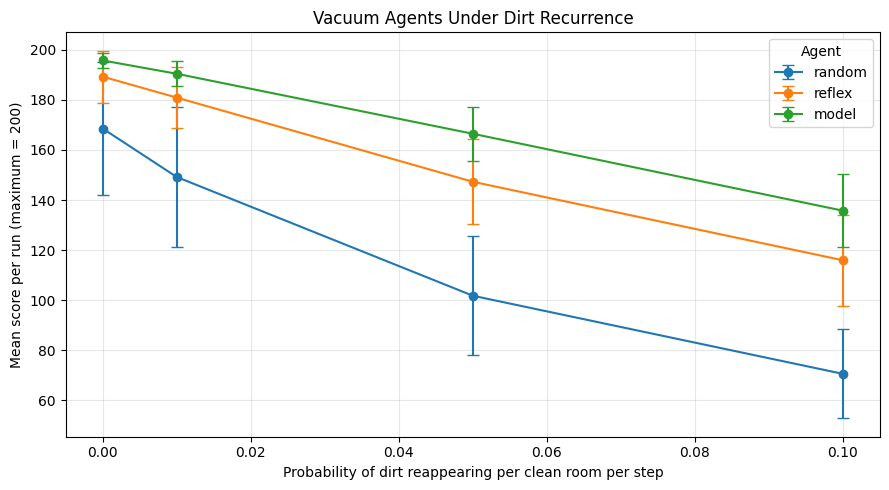

In [5]:
means = df.groupby(["dirt_probability", "agent"])["score"].mean()
stds = df.groupby(["dirt_probability", "agent"])["score"].std()

fig, ax = plt.subplots(figsize=(9, 5))

for agent in AGENTS:
    x = DIRT_PROBABILITIES
    y = [means.loc[(p, agent)] for p in x]
    errors = [stds.loc[(p, agent)] for p in x]
    ax.errorbar(x, y, yerr=errors, marker="o", capsize=4, label=agent)

ax.set_title("Vacuum Agents Under Dirt Recurrence")
ax.set_xlabel("Probability of dirt reappearing per clean room per step")
ax.set_ylabel(f"Mean score per run (maximum = {N_ROOMS * STEPS})")
ax.legend(title="Agent")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Analysis questions
1. Why is the random agent weak?
2. Why can the model-based agent stop in a static environment, but patrol in a dynamic one?
3. How does increasing the dirt-recurrence probability affect mean score and variability?
4. Are the agents compared under the same initial room layouts and environmental event schedules for each seed?

## Challenges
- Extend the environment to a 2D grid.
- Add noisy sensors.
- Add an energy cost for movement or suction.
- Compare alternative patrol policies when dirt reappears.


## Cell 7: Record frames for animation

This function follows the same action-selection and dirt-recurrence rules as `simulate`, while saving the room state after every step. The animation below uses `P_DIRT` by default.


In [7]:
def record(agent, seed=1, dirt_recurrence=P_DIRT):
    if agent not in AGENTS:
        raise ValueError(f"Unknown agent: {agent}")
    if not np.isfinite(dirt_recurrence) or not 0 <= dirt_recurrence <= 1:
        raise ValueError("dirt_recurrence must be between 0 and 1")

    initial_rng = np.random.default_rng(seed)
    action_rng = np.random.default_rng(seed + 1_000_000)
    environment_rng = np.random.default_rng(seed + 2_000_000)

    dirt = initial_rng.random(N_ROOMS) < 0.5
    dirt_events = environment_rng.random((STEPS, N_ROOMS)) < dirt_recurrence
    known_clean = np.zeros(N_ROOMS, dtype=bool)
    pos, direction, score = 0, 1, 0
    frames = [(pos, dirt.copy(), "Start", score)]

    for step in range(STEPS):
        known_clean[pos] = not dirt[pos]

        if agent == "random":
            action = action_rng.choice(("Left", "Right", "Suck"))
        elif dirt[pos]:
            action = "Suck"
        elif agent == "reflex":
            action = action_rng.choice(("Left", "Right"))
        elif dirt_recurrence == 0.0 and known_clean.all():
            action = "NoOp"
        else:
            if pos == N_ROOMS - 1:
                direction = -1
            elif pos == 0:
                direction = 1
            action = "Right" if direction == 1 else "Left"

        if action == "Suck":
            dirt[pos] = False
        elif action == "Right":
            pos = min(pos + 1, N_ROOMS - 1)
        elif action == "Left":
            pos = max(pos - 1, 0)

        dirt |= dirt_events[step] & (~dirt)
        score += int(np.count_nonzero(~dirt))
        frames.append((pos, dirt.copy(), action, score))

    return frames


## Cell 8: Animate the three agents

Each row shows an agent moving through the same initial room layout. Red rooms are dirty; green rooms are clean. Dirt recurrence is set by `P_DIRT`.

In [8]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

names = list(AGENTS)
runs = [record(agent, seed=1, dirt_recurrence=P_DIRT) for agent in names]

fig, axes = plt.subplots(3, 1, figsize=(7, 4.5), dpi=80)

def draw(t):
    for ax, name, frames in zip(axes, names, runs):
        pos, dirt_state, action, score = frames[t]
        ax.clear()
        ax.set_xlim(0, N_ROOMS)
        ax.set_ylim(0, 1)
        ax.axis("off")

        for room in range(N_ROOMS):
            color = "#fecaca" if dirt_state[room] else "#bbf7d0"
            ax.add_patch(plt.Rectangle((room + 0.05, 0.05), 0.9, 0.9, color=color))
            if dirt_state[room]:
                ax.add_patch(plt.Circle((room + 0.5, 0.35), 0.13, color="#38bdf8"))

        ax.text(pos + 0.5, 0.68, "R", fontsize=19, fontweight="bold",
                ha="center", va="center")
        ax.set_title(
            f"{name} | step {t} | action: {action} | score: {score}",
            fontsize=9,
        )

anim = FuncAnimation(fig, draw, frames=len(runs[0]), interval=250, repeat=True)
plt.close(fig)
HTML(anim.to_jshtml())


## Cell 9: Animated summary of mean scores

The bars grow toward the mean scores for every agent/probability combination.

In [9]:
mean_table = (
    df.groupby(["dirt_probability", "agent"])["score"]
    .mean()
    .unstack("agent")
    .reindex(DIRT_PROBABILITIES)
)

fig2, ax2 = plt.subplots(figsize=(9, 4.5), dpi=80)
max_score = N_ROOMS * STEPS


def grow(k):
    ax2.clear()
    progress = (k + 1) / 20
    values = mean_table * progress
    values.plot(kind="bar", ax=ax2, width=0.8)
    ax2.set_ylim(0, max_score * 1.08)
    ax2.set_title("Mean score by dirt-recurrence probability")
    ax2.set_xlabel("Dirt recurrence probability")
    ax2.set_ylabel("Mean score")
    ax2.set_xticklabels([f"{p:.0%}" for p in mean_table.index], rotation=0)
    ax2.legend(title="Agent")
    ax2.grid(axis="y", alpha=0.25)

anim2 = FuncAnimation(fig2, grow, frames=20, interval=120, repeat=False)
plt.close(fig2)
HTML(anim2.to_jshtml())
